# EDA ข้อมูลชุดใหม่: ค่าที่ขาดหาย (NULL) และคุณภาพข้อมูล

สำรวจข้อมูลหลังผ่าน notebook 02–05 แล้ว

| ชุดข้อมูล | ไฟล์ | หน่วย |
|---|---|---|
| **ตัวอย่าง (final)** | `data/processed/fossil_list_final.csv` | ตัวอย่าง 1 ชิ้น (ทะเบียน + แหล่งที่เชื่อม + ยุคสุดท้าย) |
| **แหล่ง (final)** | `data/processed/sites_period_final.geojson` | แหล่ง 1 แห่ง (ยุคสุดท้าย) |
| ต้นฉบับ (ไว้เทียบ) | `data/0301010101_fossil_list-31072567.csv`, `data/dmr_fossil_sites/fossil_sites.geojson` | |

**สารบัญ**
1. ภาพรวมและกลุ่มคอลัมน์
2. ค่าที่ขาดหายระดับตัวอย่าง: แยก "ขาดเพราะโครงสร้าง" กับ "ขาดจริง"
3. รูปแบบการขาดหาย: matrix และความสัมพันธ์ของการขาด
4. ค่าที่ทำหน้าที่เหมือนค่าว่าง (hidden nulls)
5. ก่อน vs หลังทำความสะอาด/เติมข้อมูล
6. ค่าที่ขาดหายระดับแหล่ง
7. คุณภาพข้อมูลด้านอื่น: ค่าซ้ำ ชนิดข้อมูล ความสอดคล้อง ค่าผิดปกติ การสะกดหลายแบบ
8. สรุปปัญหาและข้อแนะนำ

In [1]:
import re
from pathlib import Path

import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib import font_manager
from matplotlib.colors import LinearSegmentedColormap, ListedColormap
from rapidfuzz import fuzz, process

DATA = Path("../data")
OUT = DATA / "processed"

_installed = {f.name for f in font_manager.fontManager.ttflist}
THAI_FONT = next((f for f in ["Tahoma", "Thonburi", "Noto Sans Thai", "Leelawadee UI", "Loma", "Garuda"] if f in _installed), None)
plt.rcParams.update({
    "font.family": [THAI_FONT, "DejaVu Sans"] if THAI_FONT else ["DejaVu Sans"], "figure.dpi": 110,
    "axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": "#8a8984", "axes.labelcolor": "#52514e",
    "xtick.color": "#52514e", "ytick.color": "#52514e", "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.grid": True, "grid.color": "#e6e5e0", "grid.linewidth": 0.6, "axes.axisbelow": True,
})
pd.set_option("display.max_columns", 50, "display.max_colwidth", 60, "display.width", 160)
INK, MUTED, BAR = "#52514e", "#8a8984", "#2a78d6"

ID_DTYPES = {"fossil_id": str, "SITE_CODE": str, "site_SITE_CODE": str, "site_OBJECTID": "Int64"}
spec = pd.read_csv(OUT / "fossil_list_final.csv", dtype=ID_DTYPES, encoding="utf-8-sig", low_memory=False)
sites = gpd.read_file(OUT / "sites_period_final.geojson")
raw_spec = pd.read_csv(DATA / "0301010101_fossil_list-31072567.csv", dtype=str, encoding="utf-8-sig", keep_default_na=False)
raw_sites = gpd.read_file(DATA / "dmr_fossil_sites" / "fossil_sites.geojson")

N = len(spec)


def is_text(series):
    # pandas 3 อ่านข้อความเป็น dtype 'str' ไม่ใช่ object จึงต้องเช็กทั้งสองแบบ
    return pd.api.types.is_string_dtype(series) or series.dtype == object


print(f"ตัวอย่าง (final): {spec.shape} | แหล่ง (final): {sites.shape}")
print(f"ต้นฉบับ: ทะเบียน {raw_spec.shape} (pd.read_csv ตรง ๆ) | แหล่ง {raw_sites.shape}")

ตัวอย่าง (final): (8521, 44) | แหล่ง (final): (518, 16)
ต้นฉบับ: ทะเบียน (8524, 11) (pd.read_csv ตรง ๆ) | แหล่ง (518, 55)


## 1. ภาพรวมและกลุ่มคอลัมน์

ไฟล์ตัวอย่าง (final) มี 44 คอลัมน์ มาจาก 5 ขั้นตอน การขาดหายของแต่ละกลุ่มมีความหมายต่างกัน จึงแบ่งกลุ่มไว้ก่อน

In [2]:
GROUPS = {
    "ทะเบียนเดิม": ["fossil_id", "sci_name", "com_name", "f_group", "f_type", "f_part", "dis_name", "province", "district", "tambon", "regis_code"],
    "สร้างตอนทำความสะอาด": ["province_inferred", "district_key", "tambon_key", "genus"],
    "ผลการ merge (02)": ["match_level", "fuzzy_note", "n_candidates", "n_top", "tied_site_ids", "score", "kw", "grp", "adm", "confidence"],
    "ข้อมูลแหล่งที่เชื่อม": [c for c in spec.columns if c.startswith("site_") and not re.search(r"PERIOD_FINAL|final_", c)],
    "ยุคสุดท้าย (05)": [c for c in spec.columns if re.search(r"site_(PERIOD_FINAL|final_)", c)],
}
GROUP_COLOR = dict(zip(GROUPS, ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4"]))
COL_GROUP = {c: g for g, cs in GROUPS.items() for c in cs}
assert set(COL_GROUP) == set(spec.columns), set(spec.columns) ^ set(COL_GROUP)

overview = pd.DataFrame({
    "group": [COL_GROUP[c] for c in spec.columns],
    "dtype": spec.dtypes.astype(str).values,
    "non_null": spec.notna().sum().values,
    "missing": spec.isna().sum().values,
    "missing_%": (spec.isna().mean() * 100).round(1).values,
    "unique": spec.nunique().values,
    "example": [spec[c].dropna().astype(str).iloc[0][:40] if spec[c].notna().any() else "" for c in spec.columns],
}, index=spec.columns)
print(f"หน่วยความจำ {spec.memory_usage(deep=True).sum() / 1e6:.1f} MB | คอลัมน์ที่ไม่มีค่าว่างเลย {(overview.missing == 0).sum()} จาก {len(overview)}")
overview

หน่วยความจำ 9.4 MB | คอลัมน์ที่ไม่มีค่าว่างเลย 5 จาก 44


,group,dtype,non_null,missing,missing_%,unique,example
fossil_id,ทะเบียนเดิม,str,8521,0,0.0,8521,20200800001
sci_name,ทะเบียนเดิม,str,8028,493,5.8,740,Arionthia sapa
com_name,ทะเบียนเดิม,str,8471,50,0.6,141,แบรคิโอพอด
f_group,ทะเบียนเดิม,str,8521,0,0.0,5,Invertebrate
f_type,ทะเบียนเดิม,str,8519,2,0.0,62,แบรคิโอพอด
f_part,ทะเบียนเดิม,str,7962,559,6.6,991,Cast of valves with ventral and dorsal i
dis_name,ทะเบียนเดิม,str,5950,2571,30.2,326,คณะวิจัยร่วม การลำดับชั้นหินและบรรพชีวิน
province,ทะเบียนเดิม,str,8330,191,2.2,58,ตรัง
district,ทะเบียนเดิม,str,7832,689,8.1,236,กันตัง
tambon,ทะเบียนเดิม,str,6133,2388,28.0,279,เกาะลิบง


## 2. ค่าที่ขาดหายระดับตัวอย่าง

ค่าว่างบางส่วน**เป็นไปตามโครงสร้าง ไม่ใช่ข้อมูลหาย** เช่น ตัวอย่าง 668 ชิ้นที่ไม่ได้เชื่อมกับแหล่งใด (`match_level = none`)
ย่อมไม่มีข้อมูลแหล่ง จึงแยกนับ % ขาดหาย 2 แบบ
- **ทุกแถว**: นับตรง ๆ
- **เฉพาะที่เชื่อมแหล่งได้**: สำหรับคอลัมน์ของ merge / แหล่ง / ยุค นับเฉพาะ 7,853 ชิ้นที่มีแหล่ง เพื่อดูว่า**ขาดจริง**เท่าไร

,group,all_rows_%,linked_rows_%,real_missing_%
regis_code,ทะเบียนเดิม,93.7,-,93.7
site_GEO_GROUP,ข้อมูลแหล่งที่เชื่อม,78.3,76.5,76.5
site_PERIODFROM,ข้อมูลแหล่งที่เชื่อม,73.2,70.9,70.9
site_FORMATION,ข้อมูลแหล่งที่เชื่อม,72.0,69.6,69.6
site_LOCALITY,ข้อมูลแหล่งที่เชื่อม,60.1,56.7,56.7
genus,สร้างตอนทำความสะอาด,44.7,-,44.7
dis_name,ทะเบียนเดิม,30.2,-,30.2
tambon,ทะเบียนเดิม,28.0,-,28.0
tambon_key,สร้างตอนทำความสะอาด,28.0,-,28.0
district,ทะเบียนเดิม,8.1,-,8.1


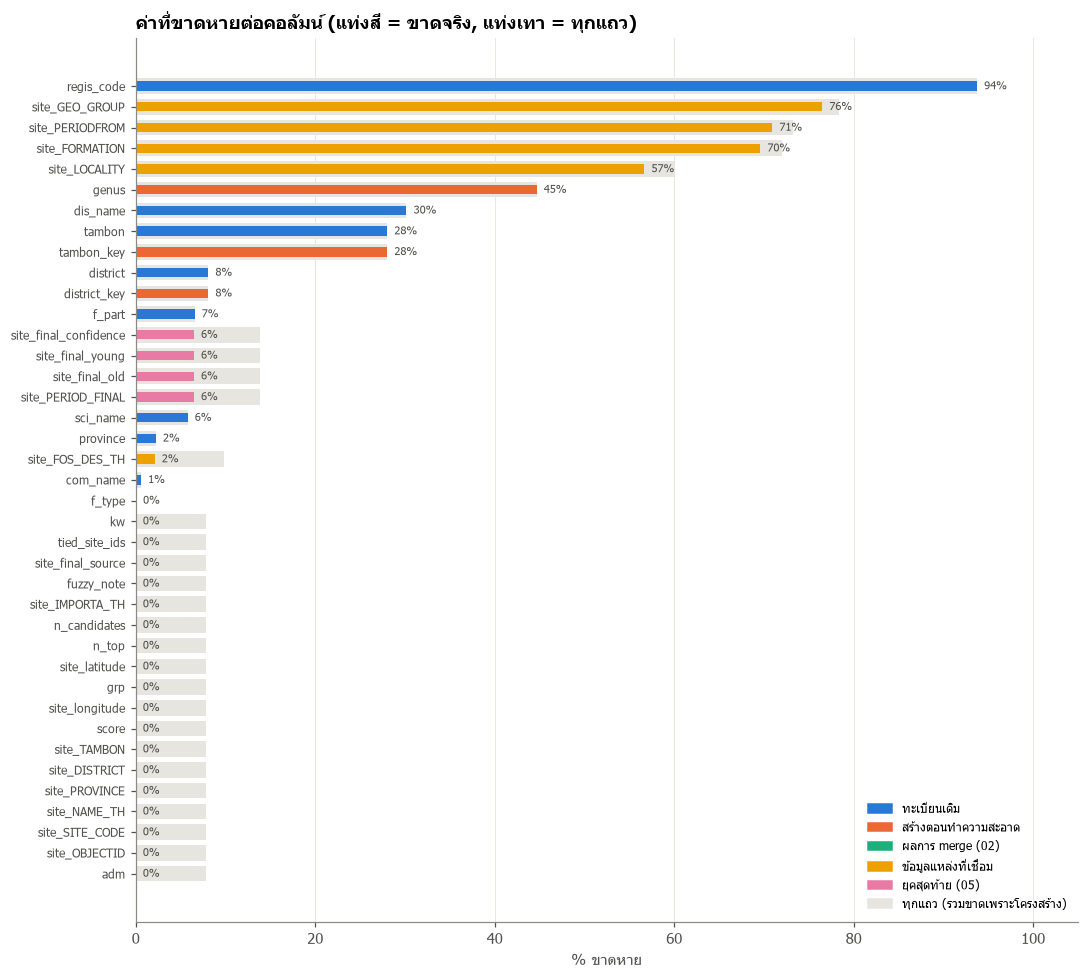

In [3]:
linked = spec.site_OBJECTID.notna()
structural = set(GROUPS["ผลการ merge (02)"] + GROUPS["ข้อมูลแหล่งที่เชื่อม"] + GROUPS["ยุคสุดท้าย (05)"]) - {"match_level", "confidence"}
miss = pd.DataFrame({
    "group": [COL_GROUP[c] for c in spec.columns],
    "all_rows_%": spec.isna().mean() * 100,
    "linked_rows_%": [spec.loc[linked, c].isna().mean() * 100 if c in structural else np.nan for c in spec.columns],
}, index=spec.columns)
miss["real_missing_%"] = miss["linked_rows_%"].fillna(miss["all_rows_%"])
show = miss[miss["all_rows_%"] > 0].sort_values("real_missing_%", ascending=False)
display(show.style.format({"all_rows_%": "{:.1f}", "linked_rows_%": "{:.1f}", "real_missing_%": "{:.1f}"}, na_rep="-"))

fig, ax = plt.subplots(figsize=(10, 9))
y = np.arange(len(show))[::-1]
ax.barh(y, show["all_rows_%"], color="#e6e5e0", height=0.75, label="ทุกแถว")
ax.barh(y, show["real_missing_%"], color=[GROUP_COLOR[g] for g in show.group], height=0.45, label="ขาดจริง")
for yi, v in zip(y, show["real_missing_%"]):
    ax.text(v + 0.8, yi, f"{v:.0f}%", va="center", fontsize=7.5, color=INK)
ax.set_yticks(y, show.index, fontsize=8)
ax.set_xlim(0, 105)
ax.set_xlabel("% ขาดหาย")
ax.grid(axis="y", visible=False)
handles = [plt.Rectangle((0, 0), 1, 1, color=GROUP_COLOR[g]) for g in GROUPS] + [plt.Rectangle((0, 0), 1, 1, color="#e6e5e0")]
ax.legend(handles, list(GROUPS) + ["ทุกแถว (รวมขาดเพราะโครงสร้าง)"], loc="lower right", frameon=False, fontsize=8)
ax.set_title("ค่าที่ขาดหายต่อคอลัมน์ (แท่งสี = ขาดจริง, แท่งเทา = ทุกแถว)")
plt.tight_layout()

อ่านกราฟ: คอลัมน์ข้อมูลแหล่งหลายคอลัมน์ขาดราว 8% ทุกแถว ซึ่ง**ทั้งหมด**มาจากตัวอย่างที่ไม่ได้เชื่อมแหล่ง (ขาดจริง 0%)
ส่วนที่ขาดจริงสูงคือ `regis_code` (เลขทะเบียน THF), คุณสมบัติของแหล่งอย่าง `site_GEO_GROUP`, `site_FORMATION`, `site_PERIODFROM`, `site_LOCALITY`,
และ `genus` (ตัวอย่างที่ยังไม่จำแนกถึงสกุล) ส่วน `site_PERIOD_FINAL` ขาดน้อยกว่า `site_PERIODFROM` มากเพราะเติมใน notebook 03–05

### การขาดหายตามกลุ่มย่อย

ค่าที่ขาดกระจายไม่เท่ากัน ดูว่าขาดมากในจังหวัด/กลุ่มซากไหน

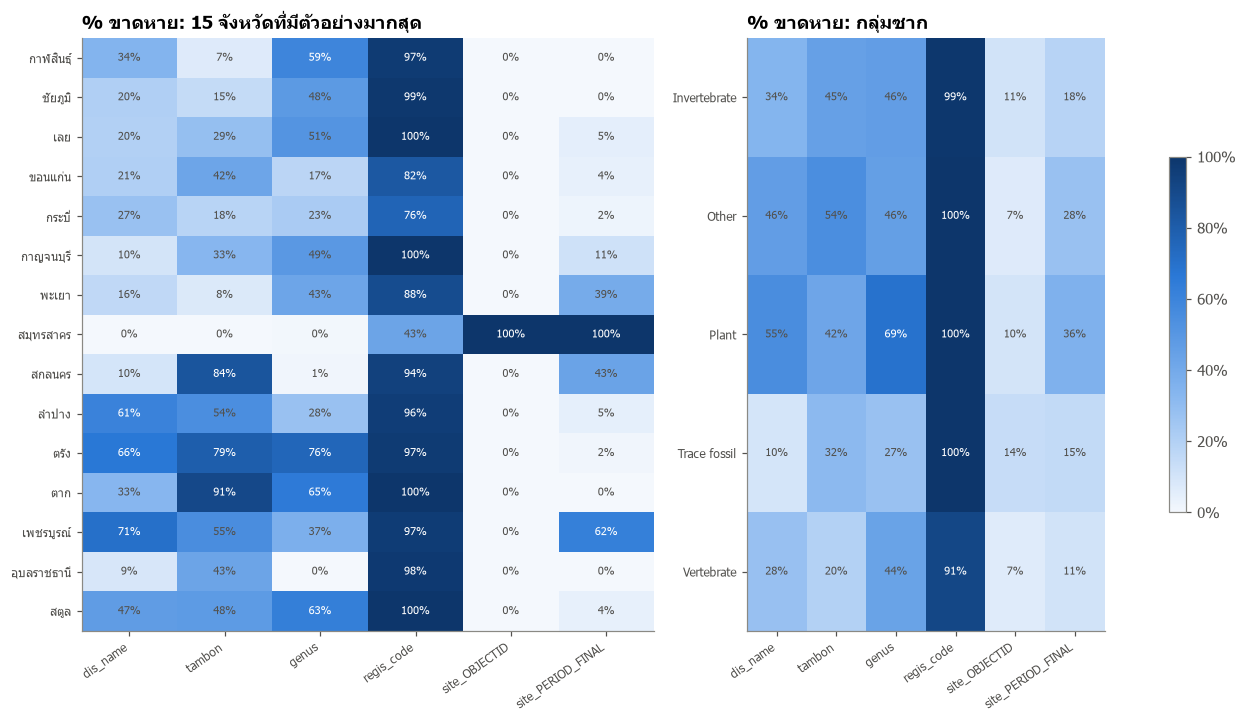

In [4]:
KEY = ["dis_name", "tambon", "genus", "regis_code", "site_OBJECTID", "site_PERIOD_FINAL"]
top_prov = spec.province.value_counts().head(15).index
by_prov = spec[KEY].isna().astype(float).groupby(spec.province).mean().reindex(top_prov)
by_group = spec[KEY].isna().astype(float).groupby(spec.f_group).mean()

blues = LinearSegmentedColormap.from_list("seq", ["#f4f8fd", "#86b6ef", "#2a78d6", "#0d366b"])
fig, axes = plt.subplots(1, 2, figsize=(15, 7), gridspec_kw={"width_ratios": [1.6, 1]})
for ax, tbl, title in [(axes[0], by_prov, "15 จังหวัดที่มีตัวอย่างมากสุด"), (axes[1], by_group, "กลุ่มซาก")]:
    im = ax.imshow(tbl.values, cmap=blues, vmin=0, vmax=1, aspect="auto")
    ax.set_xticks(range(len(KEY)), KEY, rotation=35, ha="right", fontsize=8)
    ax.set_yticks(range(len(tbl)), tbl.index, fontsize=8)
    ax.grid(False)
    for i in range(tbl.shape[0]):
        for j in range(tbl.shape[1]):
            v = tbl.values[i, j]
            ax.text(j, i, f"{v:.0%}", ha="center", va="center", fontsize=7, color="white" if v > 0.55 else INK)
    ax.set_title(f"% ขาดหาย: {title}")
fig.colorbar(im, ax=axes, shrink=0.6, format=plt.matplotlib.ticker.PercentFormatter(1))

## 3. รูปแบบการขาดหาย

### Missing matrix
แต่ละแถวคือตัวอย่าง 1 ชิ้น (เรียงตามระดับการเชื่อมแหล่ง) สีเข้ม = ขาด
ถ้าเห็นเป็น**แถบตามแนวนอน** แปลว่าหลายคอลัมน์ขาดพร้อมกันในแถวเดียวกัน (มีสาเหตุร่วม)

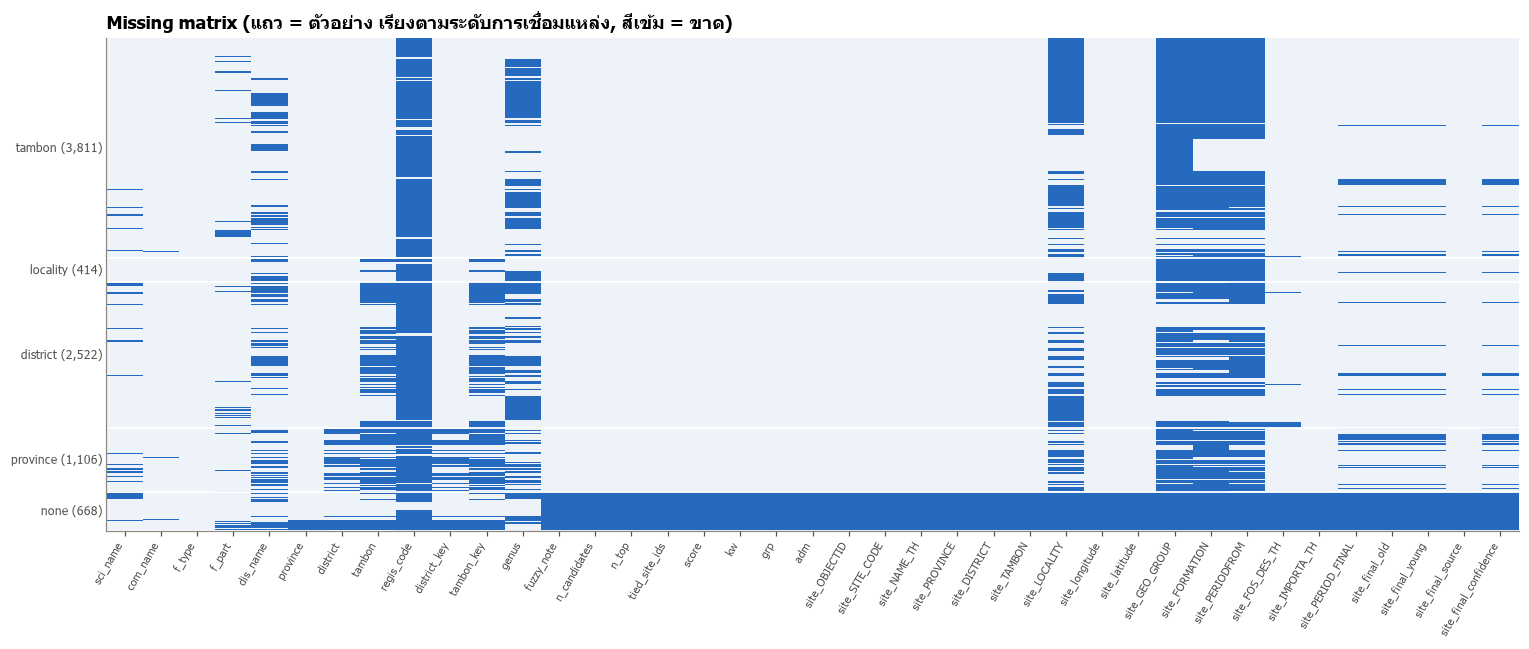

In [5]:
cols = [c for c in spec.columns if 0 < spec[c].isna().mean() < 1]
order = spec.assign(_lv=spec.match_level.map({"tambon": 0, "locality": 1, "district": 2, "province": 3, "none": 4}),
                    _p=spec.province.isna()).sort_values(["_lv", "_p", "site_OBJECTID"]).index
M = spec.loc[order, cols].isna().values

fig, ax = plt.subplots(figsize=(14, 6))
ax.imshow(M, aspect="auto", interpolation="nearest", cmap=ListedColormap(["#eef3fa", "#256abf"]))
ax.set_xticks(range(len(cols)), cols, rotation=60, ha="right", fontsize=7)
ax.set_yticks([])
ax.grid(False)
lv = spec.loc[order, "match_level"].values
for name in ["tambon", "locality", "district", "province", "none"]:
    idx = np.where(lv == name)[0]
    if len(idx):
        ax.text(-0.6, idx.mean(), f"{name} ({len(idx):,})", ha="right", va="center", fontsize=8, color=INK)
        ax.axhline(idx.max() + 0.5, color="white", lw=1.2)
ax.set_title("Missing matrix (แถว = ตัวอย่าง เรียงตามระดับการเชื่อมแหล่ง, สีเข้ม = ขาด)")
plt.tight_layout()

### ความสัมพันธ์ของการขาด (nullity correlation)

ค่าสหสัมพันธ์ระหว่าง "คอลัมน์ A ขาด" กับ "คอลัมน์ B ขาด" ใกล้ +1 = ขาดพร้อมกันเสมอ, ใกล้ −1 = ขาดสลับกัน
ตัดคอลัมน์ที่ขาดพร้อมกันเป๊ะ (ข้อมูลแหล่งทั้งชุด) ออกเหลือตัวแทนเดียว จะได้อ่านง่าย

district ขาดพร้อมกันเป๊ะกับ: district_key
tambon ขาดพร้อมกันเป๊ะกับ: tambon_key
site_OBJECTID ขาดพร้อมกันเป๊ะกับ: fuzzy_note, n_candidates, n_top, tied_site_ids, score, kw, grp, adm, site_SITE_CODE, site_NAME_TH, site_PROVINCE, site_DISTRICT, site_TAMBON, site_longitude, site_latitude, site_IMPORTA_TH, site_final_source
site_PERIOD_FINAL ขาดพร้อมกันเป๊ะกับ: site_final_old, site_final_young, site_final_confidence


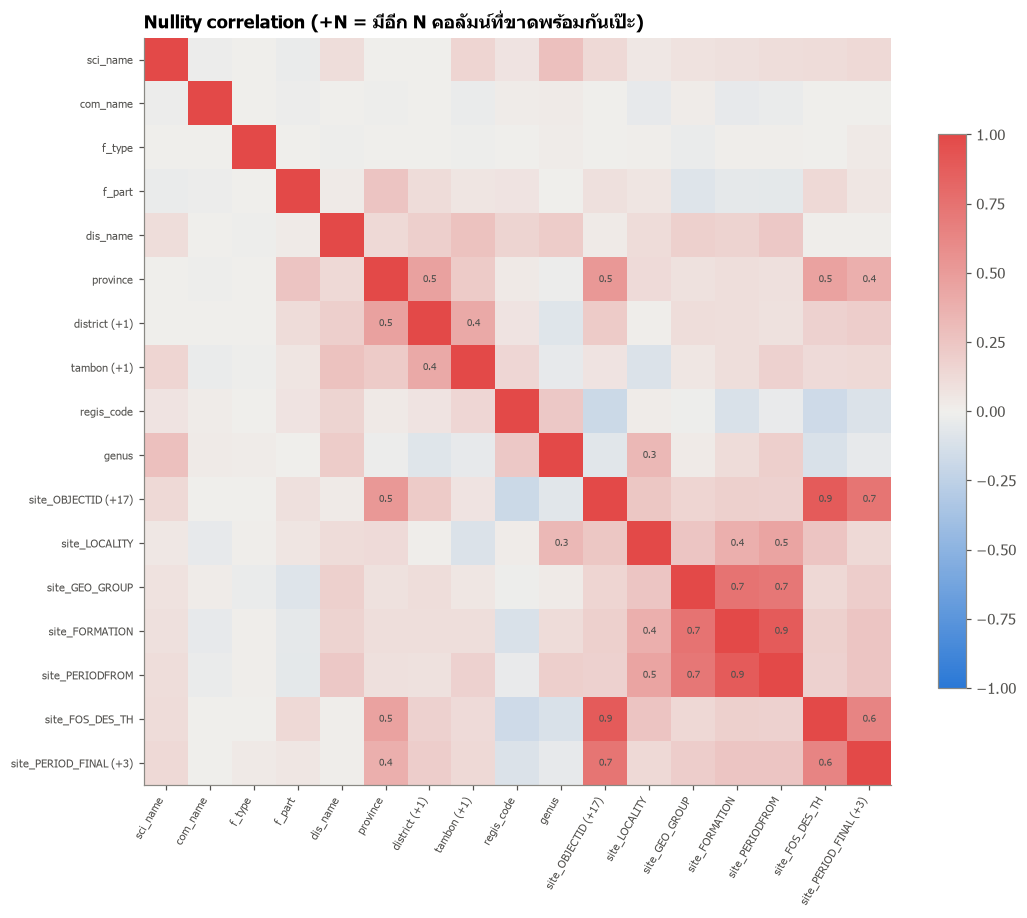

In [6]:
nul = spec[cols].isna().astype(int)
# ยุบคอลัมน์ที่รูปแบบการขาดเหมือนกันทุกแถวให้เหลือตัวแทนเดียว
sig = nul.T.apply(lambda r: hash(r.values.tobytes()), axis=1)
PREFER = ["site_OBJECTID", "site_PERIOD_FINAL", "district", "tambon"]  # ชื่อตัวแทนที่อ่านแล้วเข้าใจง่าย
rep = []
for h_ in sig.drop_duplicates():
    members = sig[sig == h_].index.tolist()
    rep.append(next((c for c in PREFER if c in members), members[0]))
rep = [c for c in cols if c in rep]
merged_note = {c: [d for d in cols if sig[d] == sig[c] and d != c] for c in rep}
corr = nul[rep].corr()

div = LinearSegmentedColormap.from_list("div", ["#2a78d6", "#f0efec", "#e34948"])
fig, ax = plt.subplots(figsize=(10, 8.5))
im = ax.imshow(corr.values, cmap=div, vmin=-1, vmax=1)
labels = [f"{c} (+{len(merged_note[c])})" if merged_note[c] else c for c in rep]
ax.set_xticks(range(len(rep)), labels, rotation=60, ha="right", fontsize=7.5)
ax.set_yticks(range(len(rep)), labels, fontsize=7.5)
ax.grid(False)
for i in range(len(rep)):
    for j in range(len(rep)):
        if i != j and abs(corr.values[i, j]) >= 0.3:
            ax.text(j, i, f"{corr.values[i, j]:.1f}", ha="center", va="center", fontsize=6.5, color=INK)
fig.colorbar(im, ax=ax, shrink=0.7)
ax.set_title("Nullity correlation (+N = มีอีก N คอลัมน์ที่ขาดพร้อมกันเป๊ะ)")
plt.tight_layout()
for c, d in merged_note.items():
    if d:
        print(f"{c} ขาดพร้อมกันเป๊ะกับ: {', '.join(d)}")

- `district` ↔ `district_key` และ `tambon` ↔ `tambon_key` ขาดพร้อมกันเสมอ (คีย์สร้างจากคอลัมน์ต้นทาง)
- ข้อมูลแหล่งทั้งชุดขาดพร้อมกันเป๊ะ (มาจากตัวอย่างที่ไม่ได้เชื่อมแหล่ง)
- `site_FORMATION`, `site_GEO_GROUP`, `site_PERIODFROM` ขาดพร้อมกันสูง (0.7–0.9) แปลว่าแหล่งที่ไม่บันทึกธรณีวิทยา มักไม่บันทึกเลยทั้งชุด
  การเติมยุคจึงต้องพึ่งข้อมูลภายนอก (PBDB, ชื่อซาก) เพราะเดาจากหมวดหินของแหล่งเดียวกันไม่ได้
- ชื่อกลุ่มซากใน `f_type` สะกดหลายแบบด้วย เช่น `ฟอแรมมินิเฟอร์` / `ฟอแรมินิเฟอร์` / `ฟอแรมินิเฟอรา` (ดูส่วน 7.3)
- `sci_name` กับ `genus`: ทุกแถวที่ไม่มี `sci_name` ก็ไม่มี `genus` แต่ `genus` ขาดมากกว่า เพราะชื่อที่ไม่ใช่ระดับสกุล (`N/A (Dinosaur)`, `Sauropod`) ก็นับเป็นขาด

## 4. ค่าที่ทำหน้าที่เหมือนค่าว่าง (hidden nulls)

ค่าที่ไม่ใช่ `NaN` แต่ไม่มีข้อมูลจริง เช่น `ไม่ระบุ`, `N/A`, `No data`, ช่องว่างล้วน, ข้อความ `nan`
นับในไฟล์ต้นฉบับเทียบกับไฟล์ final

In [7]:
HIDDEN = {"ไม่ระบุ", "n/a", "na", "no data", "-", "--", "รอการตรวจสอบ", "nan", "none", "null", "<null>", "?", ""}


def hidden_counts(df, columns):
    out = {}
    for c in columns:
        s = df[c].dropna().astype(str)
        st = s.str.strip()
        out[c] = {
            "ค่าแทนที่ว่าง": int(st.str.lower().isin(HIDDEN - {""}).sum()),
            "ว่าง/ช่องว่างล้วน": int((st == "").sum()),
            "มีช่องว่างหัว/ท้าย": int((s != st).sum()),
            "N/A (กลุ่ม)": int(st.str.match(r"^N/A\s*\(").sum()),
        }
    return pd.DataFrame(out).T


orig_cols = ["sci_name", "com_name", "f_group", "f_type", "f_part", "dis_name", "province", "district", "tambom", "regis_code"]
before = hidden_counts(raw_spec, orig_cols)
after = hidden_counts(spec.rename(columns={"tambon": "tambom"}), orig_cols)
cmp_hidden = pd.concat({"ต้นฉบับ": before, "final": after}, axis=1)
display(cmp_hidden[(cmp_hidden != 0).any(axis=1)])

site_text = [c for c in raw_sites.columns if c != "geometry" and is_text(raw_sites[c])]
hs = hidden_counts(raw_sites, site_text)
print("แหล่ง (ต้นฉบับ) คอลัมน์ที่มี hidden null หรือช่องว่างเกิน:")
hs[(hs != 0).any(axis=1)]

ต้นฉบับ                                                          final                                                 
           ค่าแทนที่ว่าง ว่าง/ช่องว่างล้วน มีช่องว่างหัว/ท้าย N/A (กลุ่ม) ค่าแทนที่ว่าง ว่าง/ช่องว่างล้วน มีช่องว่างหัว/ท้าย N/A (กลุ่ม)
sci_name             491                 3                  0        3314             0                 0                  0        3314
com_name              50                 3                  0           0             0                 0                  0           0
f_group                0                 3                  0           0             0                 0                  0           0
f_type                 0                 5                  0           0             0                 0                  0           0
f_part               559                 3                  0           0             0                 0                  0           0
dis_name            2571                 5                  0           0             0                 0                  0           0
province             712                 5                  0           0             0                 0                  0           0
district             689                 5                  0           0             0                 0                  0           0
tambom              2387                 6                  0           0             0                 0                  0           0
regis_code             0              7993                  0           0             0                 0                  0           0

แหล่ง (ต้นฉบับ) คอลัมน์ที่มี hidden null หรือช่องว่างเกิน:


,ค่าแทนที่ว่าง,ว่าง/ช่องว่างล้วน,มีช่องว่างหัว/ท้าย,N/A (กลุ่ม)
NAME_TH,0,0,38,0
NAME_ENG,0,518,0,0
LOCALITY,0,254,13,0
TAMBON,0,0,2,0
PROVINCE,0,0,1,0
FEATURE_TH,0,386,0,0
FEATURE_EN,0,518,0,0
GEO_DES_TH,0,178,41,0
GEO_DES_EN,0,518,0,0
GEO_GROUP,0,341,0,0


- ไฟล์ final ไม่มีค่าแทนที่ว่างและช่องว่างเกินเหลือแล้ว (ทำความสะอาดใน notebook 02)
- **`N/A (กลุ่ม)` ใน `sci_name` ตั้งใจเก็บไว้** เพราะบอกกลุ่มกว้างของซาก (เช่น `N/A (Dinosaur)`) แต่ต้องระวังเมื่อนับจำนวนชนิด
- ต้นฉบับของแหล่งมีช่องว่างต่อท้ายใน `FOS_GR_*` ซึ่งทำให้นับกลุ่มผิดถ้าไม่ตัดก่อน
  และค่าว่างของแหล่งเก็บเป็นข้อความว่าง `""` ไม่ใช่ NULL จริง จึงต้องแปลงก่อนนับค่าที่ขาด

## 5. ก่อน vs หลัง

,ก่อน,หลัง,หน่วย,เปลี่ยน
รายการ,,,,
ระเบียนที่อ่านผิด (fossil_id ไม่ใช่ตัวเลข),3.0,0.0,แถว,-3.0
ไม่มีจังหวัด,8.4,2.2,%,-6.2
ไม่มีอำเภอ,8.1,8.1,%,-0.1
ไม่มีตำบล,28.1,28.0,%,-0.0
ไม่มีพิกัด,100.0,7.8,%,-92.2
ไม่มียุค (ของแหล่งที่เชื่อม),100.0,13.8,%,-86.2


ระดับแหล่ง: ยุคว่าง 68.0% → 24.9%


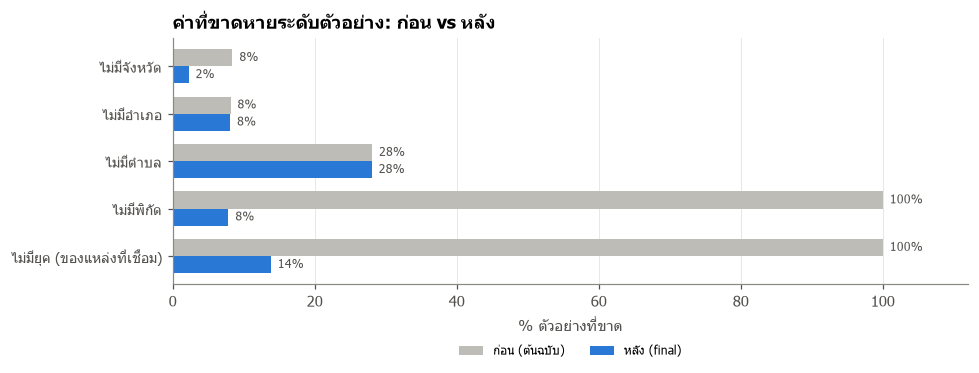

In [8]:
raw_junk = (~raw_spec.fossil_id.str.strip().str.fullmatch(r"\d+")).sum()
raw_na = lambda c: raw_spec[c].str.strip().str.lower().isin(HIDDEN).mean() * 100
rows = [
    ("ระเบียนที่อ่านผิด (fossil_id ไม่ใช่ตัวเลข)", raw_junk, 0, "แถว"),
    ("ไม่มีจังหวัด", raw_na("province"), spec.province.isna().mean() * 100, "%"),
    ("ไม่มีอำเภอ", raw_na("district"), spec.district.isna().mean() * 100, "%"),
    ("ไม่มีตำบล", raw_na("tambom"), spec.tambon.isna().mean() * 100, "%"),
    ("ไม่มีพิกัด", 100.0, spec.site_longitude.isna().mean() * 100, "%"),
    ("ไม่มียุค (ของแหล่งที่เชื่อม)", 100.0, spec.site_PERIOD_FINAL.isna().mean() * 100, "%"),
]
ba = pd.DataFrame(rows, columns=["รายการ", "ก่อน", "หลัง", "หน่วย"]).set_index("รายการ")
ba["เปลี่ยน"] = ba["หลัง"] - ba["ก่อน"]
display(ba.style.format({"ก่อน": "{:.1f}", "หลัง": "{:.1f}", "เปลี่ยน": "{:+.1f}"}))

s_rows = [("PERIODFROM / PERIOD_FINAL", sites.PERIODFROM.isna().mean() * 100, sites.PERIOD_FINAL.isna().mean() * 100)]
print("ระดับแหล่ง: ยุคว่าง %.1f%% → %.1f%%" % s_rows[0][1:])

fig, ax = plt.subplots(figsize=(9, 3.6))
pct = ba[ba["หน่วย"].eq("%")]
y = np.arange(len(pct))[::-1]
ax.barh(y + 0.18, pct["ก่อน"], height=0.36, color="#bdbcb6", label="ก่อน (ต้นฉบับ)")
ax.barh(y - 0.18, pct["หลัง"], height=0.36, color=BAR, label="หลัง (final)")
for yi, (b, a) in zip(y, zip(pct["ก่อน"], pct["หลัง"])):
    ax.text(b + 1, yi + 0.18, f"{b:.0f}%", va="center", fontsize=8, color=INK)
    ax.text(a + 1, yi - 0.18, f"{a:.0f}%", va="center", fontsize=8, color=INK)
ax.set_yticks(y, pct.index, fontsize=9)
ax.set_xlim(0, 112)
ax.set_xlabel("% ตัวอย่างที่ขาด")
ax.grid(axis="y", visible=False)
ax.legend(frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.2), ncol=2, fontsize=8)
ax.set_title("ค่าที่ขาดหายระดับตัวอย่าง: ก่อน vs หลัง")
plt.tight_layout()

## 6. ค่าที่ขาดหายระดับแหล่ง

ใช้ไฟล์แหล่งต้นฉบับ (55 คอลัมน์) ดูว่าคอลัมน์ไหนว่างทั้งหมด/ว่างมาก และไฟล์ final ดูยุคที่เติมแล้ว

คอลัมน์ว่างทั้งหมด 18 จาก 54: POTENTIAL1, POTENTIAL2, POTENTIAL4, PERIODTO, GEO_DES_EN, OWNER_ENG, FEATURE_EN, POTENTIAL7, STATUS, POTENTIAL5, POTENTIAL3, DIS_BY_ENG, DIS_BY_TH, DIS_DAY, DIS_MONTH, NAME_ENG, DIS_YEAR, POTENTIAL6


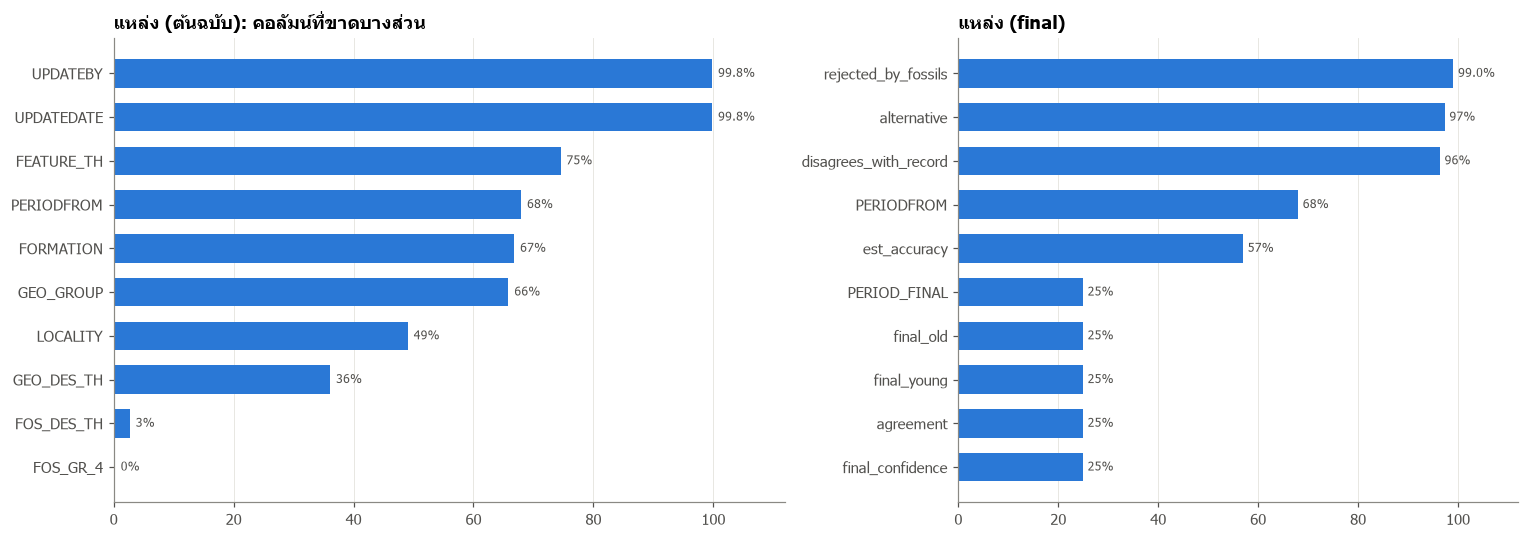

In [9]:
rs = raw_sites.drop(columns="geometry").copy()
for c in rs.columns:
    if is_text(rs[c]):
        rs[c] = rs[c].astype("string").str.strip().replace({"": pd.NA, "<Null>": pd.NA})
site_miss = (rs.isna().mean() * 100).sort_values(ascending=False)
all_empty = site_miss[site_miss == 100].index.tolist()
print(f"คอลัมน์ว่างทั้งหมด {len(all_empty)} จาก {rs.shape[1]}: {', '.join(all_empty)}")

partial = site_miss[(site_miss > 0) & (site_miss < 100)]
final_cols = sites.drop(columns="geometry").isna().mean() * 100
final_partial = final_cols[final_cols > 0]

fig, axes = plt.subplots(1, 2, figsize=(14, 5), gridspec_kw={"width_ratios": [1.2, 1]})
for ax, ser, title in [(axes[0], partial, "แหล่ง (ต้นฉบับ): คอลัมน์ที่ขาดบางส่วน"), (axes[1], final_partial.sort_values(ascending=False), "แหล่ง (final)")]:
    s_ = ser[::-1]
    ax.barh(s_.index, s_.values, color=BAR, height=0.65)
    for yi, v in enumerate(s_.values):
        ax.text(v + 1, yi, f"{v:.1f}%" if 99 < v < 100 else f"{v:.0f}%", va="center", fontsize=8, color=INK)
    ax.set_xlim(0, 112)
    ax.set_title(title)
    ax.grid(axis="y", visible=False)
plt.tight_layout()

ในไฟล์แหล่ง final คอลัมน์ `alternative`, `disagrees_with_record` ว่างเป็นส่วนใหญ่**โดยตั้งใจ** (มีค่าเฉพาะแหล่งที่คำทายขัดกัน)
และ `est_accuracy` ว่างในแหล่งที่ใช้ค่าเดิมของ ทธ. (`recorded`) ส่วนที่ขาดจริงคือ `PERIOD_FINAL` (25%) และ `PERIODFROM` ต้นฉบับ (68%)

In [10]:
tbl = pd.crosstab(sites.PROVINCE, sites.PERIOD_FINAL.isna()).rename(columns={False: "มียุค", True: "ยังว่าง"})
tbl["%ว่าง"] = tbl["ยังว่าง"] / tbl.sum(axis=1)
print("จังหวัดที่ยังมีแหล่งไม่มียุคมากสุด:")
tbl.sort_values("ยังว่าง", ascending=False).head(10).style.format({"%ว่าง": "{:.0%}"})

จังหวัดที่ยังมีแหล่งไม่มียุคมากสุด:


PERIOD_FINAL,มียุค,ยังว่าง,%ว่าง
PROVINCE,,,
สตูล,36,21,37%
อุทัยธานี,5,19,79%
เพชรบูรณ์,12,13,52%
เลย,30,10,25%
ชุมพร,7,9,56%
ชัยภูมิ,14,7,33%
หนองบัวลำภู,9,6,40%
กาญจนบุรี,10,5,33%
สุราษฎร์ธานี,1,3,75%


## 7. คุณภาพข้อมูลด้านอื่น

### 7.1 ค่าซ้ำ

In [11]:
content_cols = [c for c in GROUPS["ทะเบียนเดิม"] if c != "fossil_id"]
dup_content = spec.duplicated(subset=content_cols, keep=False)
print(f"fossil_id ซ้ำ: {spec.fossil_id.duplicated().sum()}")
print(f"ตัวอย่างที่เนื้อหาเหมือนกันทุกคอลัมน์ (ต่างแค่ fossil_id): {dup_content.sum():,} แถว ({dup_content.mean():.0%}) ใน {spec[dup_content].groupby(content_cols, dropna=False).ngroups:,} กลุ่ม")
print("  -> ปกติสำหรับทะเบียนที่ลงชิ้นส่วนหลายชิ้นจากแหล่งเดียวกัน (เช่น ฟันไดโนเสาร์หลายซี่) ไม่ใช่ข้อมูลซ้ำผิด")

print(f"\nแหล่ง: SITE_CODE ซ้ำ {sites.SITE_CODE.duplicated(keep=False).sum()} แถว | ชื่อซ้ำ {sites.NAME_TH.duplicated(keep=False).sum()} แถว")
xy = sites.geometry.apply(lambda g: (round(g.x, 5), round(g.y, 5)))
same_xy = xy.duplicated(keep=False)
print(f"แหล่งที่พิกัดซ้ำกันเป๊ะ: {same_xy.sum()} แถว")
sites.loc[sites.SITE_CODE.duplicated(keep=False) | same_xy, ["OBJECTID", "SITE_CODE", "NAME_TH", "PROVINCE"]].assign(
    xy=xy[sites.SITE_CODE.duplicated(keep=False) | same_xy]).sort_values(["SITE_CODE"])

fossil_id ซ้ำ: 0
ตัวอย่างที่เนื้อหาเหมือนกันทุกคอลัมน์ (ต่างแค่ fossil_id): 5,793 แถว (68%) ใน 853 กลุ่ม
  -> ปกติสำหรับทะเบียนที่ลงชิ้นส่วนหลายชิ้นจากแหล่งเดียวกัน (เช่น ฟันไดโนเสาร์หลายซี่) ไม่ใช่ข้อมูลซ้ำผิด

แหล่ง: SITE_CODE ซ้ำ 16 แถว | ชื่อซ้ำ 2 แถว
แหล่งที่พิกัดซ้ำกันเป๊ะ: 18 แถว


,OBJECTID,SITE_CODE,NAME_TH,PROVINCE,xy
234,11410,0139004,หอยโนนทัน,หนองบัวลำภู,"(102.51341, 17.24363)"
328,11504,0139004,สัตว์ไม่มีกระดูกสันหลังถ้ำเขาตาจีน,เพชรบุรี,"(99.95765, 12.85523)"
284,11460,0139008,สัตว์ไม่มีกระดูกสันหลังวัดถ้ำเทพานิมิต,หนองบัวลำภู,"(102.07371, 17.1535)"
501,11677,0139008,ร่องรอยซากชอนไชทางระบายน้ำล้นเขื่อนแก่งกระจาน,เพชรบุรี,"(99.62923, 12.90841)"
60,11235,0139009,แบรคิโอพอดวัดป่าผาสุกคามเขต,หนองบัวลำภู,"(102.04232, 17.15539)"
500,11676,0139009,ปะการังเขาตกน้ำ,เพชรบุรี,"(99.70417, 12.84666)"
64,11239,0139010,สัตว์ไม่มีกระดูกสันหลังบ้านไทสามัคคี,หนองบัวลำภู,"(102.02819, 17.19629)"
499,11675,0139010,สัตว์ไม่มีกระดูกสันหลังเขาบันไดอิฐ (ทางเข้าวัดเขาบันไดอิฐ),เพชรบุรี,"(99.92862, 13.10327)"
65,11240,0139011,หอยภูเก้า,หนองบัวลำภู,"(102.47899, 16.9355)"
498,11674,0139011,สัตว์ไม่มีกระดูกสันหลังถ้ำจันทน์,เพชรบุรี,"(99.93231, 13.1357)"


### 7.2 ชนิดข้อมูลและรูปแบบรหัส

In [12]:
checks = {
    "fossil_id เป็นตัวเลข 11 หลัก": spec.fossil_id.str.fullmatch(r"\d{11}").all(),
    "site_SITE_CODE เป็นตัวเลข 7 หลัก (มี 0 นำหน้า)": spec.site_SITE_CODE.dropna().str.fullmatch(r"\d{7}").all(),
    "SITE_CODE แหล่งเป็นตัวเลข 7 หลัก": sites.SITE_CODE.str.fullmatch(r"\d{7}").all(),
    "site_OBJECTID เป็นจำนวนเต็ม (ไม่ใช่ทศนิยม)": str(spec.site_OBJECTID.dtype) == "Int64",
    "regis_code รูปแบบ THF <ปี พ.ศ.> <ประเภท> <ลำดับ>": spec.regis_code.dropna().str.fullmatch(r"THF \d{4} \d \d{5}").mean(),
    "province_inferred เป็น True/False": set(spec.province_inferred.dropna().astype(str)) <= {"True", "False"},
}
pd.Series(checks, name="ผ่าน").to_frame()

,ผ่าน
fossil_id เป็นตัวเลข 11 หลัก,True
site_SITE_CODE เป็นตัวเลข 7 หลัก (มี 0 นำหน้า),True
SITE_CODE แหล่งเป็นตัวเลข 7 หลัก,True
site_OBJECTID เป็นจำนวนเต็ม (ไม่ใช่ทศนิยม),True
regis_code รูปแบบ THF <ปี พ.ศ.> <ประเภท> <ลำดับ>,1.0
province_inferred เป็น True/False,True


**หมายเหตุ**: ก่อนรอบนี้ `site_SITE_CODE` ในไฟล์ของ notebook 03/05 เสีย 0 นำหน้า (`0192003` → `192003.0`) เพราะอ่าน CSV โดยไม่กำหนดชนิดข้อมูล
แก้แล้วทั้งต้นทาง (02 เขียน `site_OBJECTID` เป็น `Int64`) และปลายทาง (03–05 อ่านคอลัมน์รหัสเป็นข้อความ) **ถ้าอ่านไฟล์เหล่านี้เองให้ใช้**
`pd.read_csv(..., dtype={"fossil_id": str, "SITE_CODE": str, "site_SITE_CODE": str})`

### 7.3 ความสอดคล้องระหว่างคอลัมน์

In [13]:
lk = spec[linked]
prov_mismatch = lk.province.notna() & lk.province.ne(lk.site_PROVINCE)
dist_match = lk.district_key.notna() & lk.match_level.isin(["tambon", "district"])
period_ok = sites.dropna(subset=["final_old"])
ORDER = ["Precambrian", "Cambrian", "Ordovician", "Silurian", "Devonian", "Carboniferous", "Permian",
         "Triassic", "Jurassic", "Cretaceous", "Tertiary", "Quaternary"]
R = {p: i for i, p in enumerate(ORDER)}
ct_type = spec.groupby("com_name").f_type.nunique()
ct_group = spec.groupby("f_type").f_group.nunique()

consistency = pd.DataFrame([
    ("จังหวัดของตัวอย่าง ≠ จังหวัดของแหล่งที่เชื่อม", prov_mismatch.sum(), len(lk)),
    ("ยุค final_old อ่อนกว่า final_young (ช่วงกลับด้าน)", (period_ok.final_old.map(R) > period_ok.final_young.map(R)).sum(), len(period_ok)),
    ("ยุคที่เติม ขัดกับ PERIODFROM เดิม (disagrees_with_record)", sites.disagrees_with_record.notna().sum(), sites.PERIODFROM.notna().sum()),
    ("com_name เดียวแต่มีหลาย f_type", (ct_type > 1).sum(), len(ct_type)),
    ("f_type เดียวแต่มีหลาย f_group", (ct_group > 1).sum(), len(ct_group)),
    ("แหล่งไดโนเสาร์ (ตามชื่อ) ที่ยุคสุดท้ายเก่ากว่าไทรแอสซิก",
     (sites.NAME_TH.str.contains("ไดโนเสาร์", na=False) & sites.final_old.map(R).lt(R["Triassic"])).sum(),
     sites.NAME_TH.str.contains("ไดโนเสาร์", na=False).sum()),
], columns=["การตรวจ", "พบ", "จาก"])
display(consistency)

print("ตัวอย่าง f_type ที่มีหลาย f_group:")
display(spec[spec.f_type.isin(ct_group[ct_group > 1].index)].groupby(["f_type", "f_group"]).size().rename("ตัวอย่าง").to_frame().head(12))
print("แหล่งไดโนเสาร์ที่ยุคเป็นไปไม่ได้:")
sites[sites.NAME_TH.str.contains("ไดโนเสาร์", na=False) & sites.final_old.map(R).lt(R["Triassic"])][
    ["NAME_TH", "PROVINCE", "PERIOD_FINAL", "final_source", "final_confidence", "alternative"]]

,การตรวจ,พบ,จาก
0,จังหวัดของตัวอย่าง ≠ จังหวัดของแหล่งที่เชื่อม,0,7853
1,ยุค final_old อ่อนกว่า final_young (ช่วงกลับด้าน),0,389
2,ยุคที่เติม ขัดกับ PERIODFROM เดิม (disagrees_with_record),19,166
3,com_name เดียวแต่มีหลาย f_type,22,141
4,f_type เดียวแต่มีหลาย f_group,14,62
5,แหล่งไดโนเสาร์ (ตามชื่อ) ที่ยุคสุดท้ายเก่ากว่าไทรแอสซิก,0,55


ตัวอย่าง f_type ที่มีหลาย f_group:


ตัวอย่าง
f_type         f_group               
จระเข้         Invertebrate         1
               Vertebrate         403
ปลากระดูกอ่อน  Invertebrate         3
               Vertebrate         245
ปลากระดูกแข็ง  Invertebrate         1
               Vertebrate         454
ฟอแรมมินิเฟอร์ Invertebrate         4
               Other               81
ฟอแรมินิเฟอรา  Invertebrate         4
               Other                3
ฟอแรมินิเฟอร์  Invertebrate         7
               Other               42

แหล่งไดโนเสาร์ที่ยุคเป็นไปไม่ได้:


,NAME_TH,PROVINCE,PERIOD_FINAL,final_source,final_confidence,alternative


ไดโนเสาร์ปรากฏครั้งแรกในยุคไทรแอสซิก แหล่งไดโนเสาร์ที่ยุคเก่ากว่านั้นจึง**ผิดแน่นอน** — notebook 05 ส่วน 2b ใช้กฎนี้
(และกฎของไทรโลไบต์ / แกรปโตไลต์ / สัตว์เลี้ยงลูกด้วยนม) ตัดคำทายที่เป็นไปไม่ได้ก่อนรวมแล้ว ตารางนี้จึงควรว่าง

### 7.4 ค่าผิดปกติ (outliers)

แหล่งที่พิกัดอยู่นอกกรอบประเทศไทย: 0
ตัวอย่างต่อแหล่ง (แบ่งน้ำหนักกรณีเสมอ): มัธยฐาน 3.0, 90th 35, สูงสุด 688 | ถ้านับจาก site_OBJECTID ตรง ๆ สูงสุดจะเป็น 1,026 (เพี้ยนจากการตัดสินเสมอ)


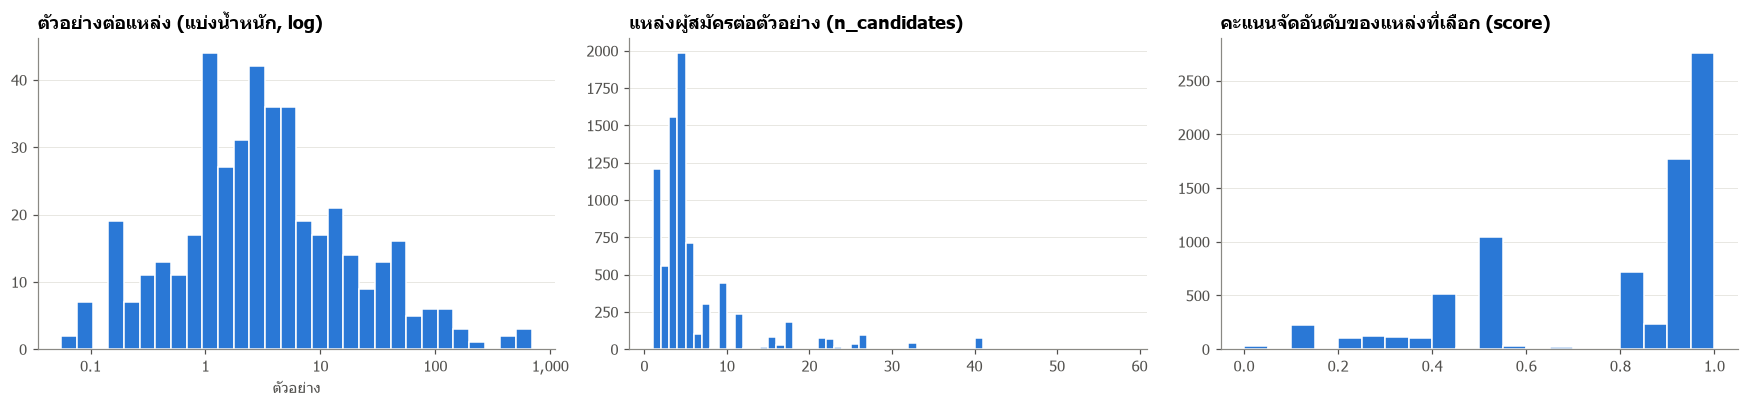

In [14]:
in_th = sites.geometry.x.between(97.3, 105.7) & sites.geometry.y.between(5.6, 20.5)
# นับแบบแบ่งน้ำหนัก: ตัวอย่างที่เสมอกัน k แหล่ง ให้แต่ละแหล่ง 1/k (ไม่นับจาก site_OBJECTID ที่ถูกเลือกตอนตัดสินเสมอ)
tied = spec.dropna(subset=["tied_site_ids"]).assign(sid=lambda d: d.tied_site_ids.str.split(";")).explode("sid")
tied["w"] = 1 / tied.groupby("fossil_id").sid.transform("size")
per_site = tied.groupby("sid").w.sum()
naive_max = spec.groupby("site_OBJECTID").size().max()
print(f"แหล่งที่พิกัดอยู่นอกกรอบประเทศไทย: {(~in_th).sum()}")
print(f"ตัวอย่างต่อแหล่ง (แบ่งน้ำหนักกรณีเสมอ): มัธยฐาน {per_site.median():.1f}, 90th {per_site.quantile(.9):.0f}, สูงสุด {per_site.max():,.0f}"
      f" | ถ้านับจาก site_OBJECTID ตรง ๆ สูงสุดจะเป็น {naive_max:,} (เพี้ยนจากการตัดสินเสมอ)")

fig, axes = plt.subplots(1, 3, figsize=(16, 3.8))
axes[0].hist(np.log10(per_site.values.astype(float)), bins=30, color=BAR, edgecolor="white")
axes[0].set_xticks([-1, 0, 1, 2, 3], ["0.1", "1", "10", "100", "1,000"])
axes[0].set_title("ตัวอย่างต่อแหล่ง (แบ่งน้ำหนัก, log)")
axes[0].set_xlabel("ตัวอย่าง")
axes[1].hist(spec.n_candidates.dropna(), bins=range(1, int(spec.n_candidates.max()) + 2), color=BAR, edgecolor="white")
axes[1].set_title("แหล่งผู้สมัครต่อตัวอย่าง (n_candidates)")
axes[2].hist(spec.score.dropna(), bins=20, color=BAR, edgecolor="white")
axes[2].set_title("คะแนนจัดอันดับของแหล่งที่เลือก (score)")
for ax in axes:
    ax.grid(axis="x", visible=False)
plt.tight_layout()

ตัวอย่างต่อแหล่งเบ้ขวามาก (แหล่งขุดค้นไดโนเสาร์ไม่กี่แห่งมีหลายร้อยชิ้น) ค่าสูงสุดจึงไม่ใช่ข้อผิดพลาด
แต่ควรใช้มัธยฐานหรือ log เวลาสรุป

### 7.5 ข้อความอิสระที่สะกดหลายแบบ

`dis_name` (ผู้ค้นพบ) เป็นข้อความอิสระ ชื่อคณะเดียวกันเขียนได้หลายแบบ จับกลุ่มชื่อที่คล้ายกัน (`fuzz.token_set_ratio` ≥ 85)

In [15]:
names = spec.dis_name.value_counts()
uniq = names.index.tolist()
clusters, assigned = [], set()
for nm in uniq:  # เรียงจากพบบ่อยไปน้อย ชื่อแรกของกลุ่มเป็นตัวแทน
    if nm in assigned:
        continue
    sim = process.extract(nm, [u for u in uniq if u not in assigned], scorer=fuzz.token_set_ratio, score_cutoff=85, limit=None)
    members = [m for m, _, _ in sim]
    assigned |= set(members)
    if len(members) > 1:
        clusters.append((nm, len(members), int(names[members].sum()), members[1:4]))
cl = pd.DataFrame(clusters, columns=["ตัวแทน", "ชื่อในกลุ่ม", "ตัวอย่าง", "ตัวอย่างชื่อที่รวม"]).sort_values("ตัวอย่าง", ascending=False)
print(f"dis_name {len(uniq)} ค่า → กลุ่มที่มีหลายชื่อ {len(cl)} กลุ่ม (ครอบคลุม {cl['ชื่อในกลุ่ม'].sum()} ชื่อ)")
cl.head(12)

dis_name 326 ค่า → กลุ่มที่มีหลายชื่อ 60 กลุ่ม (ครอบคลุม 136 ชื่อ)


,ตัวแทน,ชื่อในกลุ่ม,ตัวอย่าง,ตัวอย่างชื่อที่รวม
1,คณะสำรวจโบราณชีววิทยาไทย-ฝรั่งเศส,3,927,"[คณะสำรวจโบราณชีววิทยาไทย - ฝรั่งเศส, คณะสำรวจวิจัยโบราณ..."
2,กรมทรัพยากรธรณี,3,747,"[กรมทรัพยากรธรณี และวราวุธ สุธีธร, กรมทรัพยากรธรณี และลั..."
0,ทีมสำรวจไทย-ฝรั่งเศส,2,672,[ทีมไทย-ฝรั่งเศส]
3,ศักดิ์ชัย จวนงาม และคณะ,2,441,[ศักดิ์ชัย จวนงาม]
4,โส สุวรรณไตร,2,158,[โส สุวรรณไตร และคณะ]
6,สิโรฒม์ ศัลยพงษ์,3,111,"[สิโรตม์ ศัลยพงษ์, นายสิโรฒม์ ศัลยพงษ์]"
5,วราวุธ สุธีธร และคณะ,2,107,[นายวราวุธ สุธีธร และคณะ]
9,จรัล ภูไท,2,74,[จรัญ ภูไท]
10,สมาน บุราวาศ,2,69,[สมาน บุราวาศ และคณะ]
7,ชัยยันต์ หินทอง,2,49,[ชัยยันต์ หินทอง และคณะ]


การจับกลุ่มอัตโนมัติช่วยหาตัวเลือก แต่ยังต้องให้คนตรวจ เพราะบางกลุ่มรวมคนละคณะที่ชื่อคล้ายกัน
`f_part` (ส่วนของซาก ~990 ค่า ผสมไทย/อังกฤษ) ก็มีปัญหาแบบเดียวกัน

## 8. สรุปปัญหาและข้อแนะนำ

In [16]:
summary = pd.DataFrame([
    ("ทะเบียน", "regis_code (เลขทะเบียน THF) ขาด", f"{spec.regis_code.isna().mean():.0%}", "สูง", "ขอข้อมูลเลขทะเบียนจากต้นทาง ใช้ fossil_id เป็นคีย์ไปก่อน"),
    ("ทะเบียน", "dis_name (ผู้ค้นพบ) ขาด + สะกดหลายแบบ", f"{spec.dis_name.isna().mean():.0%} / {len(cl)} กลุ่ม", "กลาง", "ทำตาราง mapping ชื่อคณะ (เริ่มจากกลุ่มในส่วน 7.5)"),
    ("ทะเบียน", "tambon ขาด", f"{spec.tambon.isna().mean():.0%}", "กลาง", "ทำให้เชื่อมแหล่งได้แค่ระดับอำเภอ/จังหวัด"),
    ("ทะเบียน", "ยังไม่จำแนกถึงสกุล (genus ว่าง)", f"{spec.genus.isna().mean():.0%}", "กลาง", "ธรรมชาติของข้อมูล ใช้ broad taxon ใน sci_name แทน"),
    ("merge", "ตัวอย่างที่ไม่ได้เชื่อมแหล่ง (ไม่มีพิกัด)", f"{(~linked).mean():.0%}", "กลาง", "ส่วนใหญ่มาจากจังหวัดที่ไม่มีแหล่งใน DB (เช่น สมุทรสาคร)"),
    ("merge", "เชื่อมแหล่งด้วยความเชื่อมั่น low", f"{spec.confidence.eq('low').mean():.0%}", "กลาง", "กรอง confidence != 'low' เมื่อวิเคราะห์ระดับแหล่ง"),
    ("แหล่ง", "คุณสมบัติธรณีวิทยา (FORMATION, GEO_GROUP) ขาด", f"{rs.FORMATION.isna().mean():.0%}", "กลาง", "เติมจากแผนที่หน่วยหิน (notebook 01 ส่วน 5)"),
    ("แหล่ง", "PERIOD_FINAL ยังว่าง", f"{sites.PERIOD_FINAL.isna().mean():.0%}", "กลาง", "เติมจากแผนที่หน่วยหิน (เป็นอายุหิน)"),
    ("แหล่ง", "คอลัมน์ว่างทั้งหมด", f"{len(all_empty)} คอลัมน์", "ต่ำ", "ตัดทิ้ง"),
    ("แหล่ง", "แหล่งไดโนเสาร์ที่ยุคเป็นไปไม่ได้", f"{consistency.set_index('การตรวจ').loc['แหล่งไดโนเสาร์ (ตามชื่อ) ที่ยุคสุดท้ายเก่ากว่าไทรแอสซิก', 'พบ']} แหล่ง", "สูง",
     "notebook 05 ส่วน 2b ตัดคำทายที่ขัดกับซากแล้ว (คอลัมน์ rejected_by_fossils)"),
    ("แหล่ง", "SITE_CODE ชนกันข้ามจังหวัด (เช่น 0139xxx ใช้ทั้งเพชรบุรีและหนองบัวลำภู)", f"{sites.SITE_CODE.duplicated(keep=False).sum()} แถว", "กลาง", "ใช้ OBJECTID เป็นคีย์แทน SITE_CODE"),
    ("ทะเบียน", "ชื่อ f_type / com_name สะกดหลายแบบ (เช่น ฟอแรมมินิเฟอร์/ฟอแรมินิเฟอรา)", f"{(ct_type > 1).sum()} com_name", "ต่ำ", "ทำตาราง mapping ชื่อกลุ่มซาก"),
    ("ไฟล์", "รหัสเสีย 0 นำหน้าเมื่ออ่าน CSV", "แก้แล้ว", "สูง", "อ่านด้วย dtype=str ทุกครั้ง"),
], columns=["ชุดข้อมูล", "ปัญหา", "ขนาด", "ความรุนแรง", "ข้อแนะนำ"])
summary

,ชุดข้อมูล,ปัญหา,ขนาด,ความรุนแรง,ข้อแนะนำ
0,ทะเบียน,regis_code (เลขทะเบียน THF) ขาด,94%,สูง,ขอข้อมูลเลขทะเบียนจากต้นทาง ใช้ fossil_id เป็นคีย์ไปก่อน
1,ทะเบียน,dis_name (ผู้ค้นพบ) ขาด + สะกดหลายแบบ,30% / 60 กลุ่ม,กลาง,ทำตาราง mapping ชื่อคณะ (เริ่มจากกลุ่มในส่วน 7.5)
2,ทะเบียน,tambon ขาด,28%,กลาง,ทำให้เชื่อมแหล่งได้แค่ระดับอำเภอ/จังหวัด
3,ทะเบียน,ยังไม่จำแนกถึงสกุล (genus ว่าง),45%,กลาง,ธรรมชาติของข้อมูล ใช้ broad taxon ใน sci_name แทน
4,merge,ตัวอย่างที่ไม่ได้เชื่อมแหล่ง (ไม่มีพิกัด),8%,กลาง,ส่วนใหญ่มาจากจังหวัดที่ไม่มีแหล่งใน DB (เช่น สมุทรสาคร)
5,merge,เชื่อมแหล่งด้วยความเชื่อมั่น low,23%,กลาง,กรอง confidence != 'low' เมื่อวิเคราะห์ระดับแหล่ง
6,แหล่ง,"คุณสมบัติธรณีวิทยา (FORMATION, GEO_GROUP) ขาด",67%,กลาง,เติมจากแผนที่หน่วยหิน (notebook 01 ส่วน 5)
7,แหล่ง,PERIOD_FINAL ยังว่าง,25%,กลาง,เติมจากแผนที่หน่วยหิน (เป็นอายุหิน)
8,แหล่ง,คอลัมน์ว่างทั้งหมด,18 คอลัมน์,ต่ำ,ตัดทิ้ง
9,แหล่ง,แหล่งไดโนเสาร์ที่ยุคเป็นไปไม่ได้,0 แหล่ง,สูง,notebook 05 ส่วน 2b ตัดคำทายที่ขัดกับซากแล้ว (คอลัมน์ re...
